# DSRA-Net on a second dataset: RSNA Pneumonia Detection Challenge

**Why:** shows that DSRA-Net is not tuned to one dataset. RSNA is very different from Kermany: **adult** chest X-rays
(from the NIH ChestX-ray14 collection, USA) instead of paediatric ones (Guangzhou, China), labelled by radiologists,
and it has **boxes drawn around every pneumonia region**, so Grad-CAM can be checked against real lesion locations.

**Task (standard binary setting):** *Lung Opacity* (pneumonia, 6,012 images) vs *Normal* (8,851 images).
The third class *"No Lung Opacity / Not Normal"* (other diseases) is left out, as in most binary pneumonia papers.
RSNA has one image per patient, so every split is automatically patient-wise.

**Protocol:** 3 different random patient splits (70% train / 15% validation / 15% test, stratified), one DSRA-Net per split,
trained **exactly like the Kermany v2 model** (same architecture, pre-processing, augmentation, loss and schedule).
Results are reported as **mean ± std over the 3 splits**. Nothing is tuned on the test sets.

**How to run on Kaggle**
1. **Join the competition once:** open kaggle.com/competitions/rsna-pneumonia-detection-challenge → *Join Competition* /
   accept the rules (late use of the data is allowed).
2. **Add the data:** in this notebook → *Add Input* → *Competitions* → **RSNA Pneumonia Detection Challenge** → *Add*.
3. **GPU:** *Settings → Accelerator → GPU T4 x2* (one GPU is used). If `pydicom` is missing, turn *Internet* on in *Settings*.
4. **Run:** *Save Version → Save & Run All*. About **2–3 hours** (reading ~15,000 DICOM files + 3 training runs).
5. **Results:** tables (CSV) and figures (300-dpi PNG) in `/kaggle/working/outputs` (*Output* tab).

## 1. Setup and settings

In [1]:
import os, re, gc, json, time, warnings, subprocess, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
T0 = time.time()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display

try:
    import pydicom
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydicom"], check=False)
    import pydicom

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, roc_curve,
                             matthews_corrcoef, average_precision_score)

print("TensorFlow:", tf.__version__, "| Keras:", getattr(keras, "__version__", "n/a"), "| pydicom:", pydicom.__version__)
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print("Could not set memory growth:", e)
print("GPU:", [g.name for g in gpus] if gpus else "NONE -> turn on a GPU (Settings > Accelerator)")

# ============================ SETTINGS (edit here) ============================
SEEDS             = [42, 142, 242]   # 3 different patient splits, one model each
TRAIN_FRAC        = 0.70             # 70% train, 15% validation, 15% test
VAL_FRAC          = 0.15
TIME_BUDGET_HOURS = 11.0             # no new run is started after this (Kaggle stops a session at 12 hours)
# ---- identical to the Kermany DSRA-Net v2 notebook ----
IMG_SIZE, CROP_MARGIN = 224, 0.03
BATCH_SIZE, EPOCHS, LEARNING_RATE = 32, 60, 1e-3
L2_WEIGHT, LABEL_SMOOTHING, BN_MOMENTUM = 1e-4, 0.1, 0.9
ES_PATIENCE, LR_PATIENCE, THRESHOLD = 10, 3, 0.5
CLASS_NAMES = ["Normal", "Pneumonia"]
# ==============================================================================

QUICK_TEST = os.environ.get("DSRA_QUICK", "0") == "1"   # tiny smoke test only; leave off on Kaggle
if QUICK_TEST:
    IMG_SIZE, EPOCHS, SEEDS = 96, int(os.environ.get("DSRA_EPOCHS", "1")), [42]
    print("QUICK_TEST mode: tiny run for checking the code; the numbers are meaningless.")

OUT_DIR = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else os.path.abspath("outputs")
FIG_DIR, TAB_DIR, MODEL_DIR = (os.path.join(OUT_DIR, d) for d in ("figures", "tables", "models_rsna"))
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE
keras.utils.set_random_seed(SEEDS[0])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
C_NORMAL, C_PNEU = "#2F6DB5", "#D1495B"


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_table(table, name, index=False):
    table.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), index=index)


def safe(fn):
    # figures and extras never stop the notebook: an error is printed and the run continues
    try:
        fn()
    except Exception as e:
        print(f"[skipped {getattr(fn, '__name__', 'step')}] {type(e).__name__}: {str(e)[:300]}")


print("Outputs folder:", OUT_DIR)

TensorFlow: 2.20.0 | Keras: 3.13.2 | pydicom: 3.0.2
GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']
Outputs folder: /kaggle/working/outputs


## 2. Find the RSNA data and build the image list
Labels come from `stage_2_detailed_class_info.csv` (class per patient) and `stage_2_train_labels.csv` (pneumonia boxes).

In [2]:
def find_file(name):
    for base in [os.environ.get("RSNA_ROOT", ""), "/kaggle/input", os.path.abspath("input")]:
        if base and os.path.isdir(base):
            for dirpath, _, files in os.walk(base):
                if name in files:
                    return os.path.join(dirpath, name)
    return None


info_path = find_file("stage_2_detailed_class_info.csv")
labels_path = find_file("stage_2_train_labels.csv")
if info_path is None or labels_path is None:
    raise FileNotFoundError("RSNA label files not found. Join the competition 'rsna-pneumonia-detection-challenge', then "
                            "Add Input -> Competitions -> RSNA Pneumonia Detection Challenge.")
info = pd.read_csv(info_path).drop_duplicates("patientId")
box_df = pd.read_csv(labels_path)
print("Label files:", info_path, "|", labels_path)
display(info["class"].value_counts().rename("images").to_frame())

keep = info[info["class"].isin(["Lung Opacity", "Normal"])].copy()
wanted = set(keep["patientId"])
img_path = {}
for base in [os.path.dirname(info_path), os.environ.get("RSNA_ROOT", ""), "/kaggle/input"]:
    if not base or not os.path.isdir(base):
        continue
    for dirpath, dirnames, files in os.walk(base):
        dirnames[:] = [d for d in dirnames if "test" not in d.lower() and "__macosx" not in d.lower()]
        for f in files:
            stem, ext = os.path.splitext(f)
            if stem in wanted and stem not in img_path and ext.lower() in (".dcm", ".png", ".jpg", ".jpeg"):
                img_path[stem] = os.path.join(dirpath, f)
    if len(img_path) >= len(wanted):
        break
keep["path"] = keep["patientId"].map(img_path)
missing = int(keep["path"].isna().sum())
if missing:
    print(f"WARNING: {missing} images listed in the labels were not found and are left out.")
df = keep.dropna(subset=["path"]).reset_index(drop=True)
df["label"] = (df["class"] == "Lung Opacity").astype(int)
assert df["patientId"].is_unique, "one image per patient expected"

if QUICK_TEST:
    df = pd.concat([df[df["label"] == 0].head(150), df[df["label"] == 1].head(100)]).reset_index(drop=True)

counts = df["class"].value_counts().rename("images").to_frame()
print(f"Used for the binary task: {len(df)} images (one per patient)")
display(counts)
save_table(counts, "rsna_dataset_counts", index=True)

Label files: /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_detailed_class_info.csv | /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv


,images
class,
No Lung Opacity / Not Normal,11821
Normal,8851
Lung Opacity,6012


Used for the binary task: 14863 images (one per patient)


,images
class,
Normal,8851
Lung Opacity,6012


## 3. Load all images (same pre-processing as Kermany)
Grayscale → black-border removal + 3% trim → 224×224. The crop of every image is stored so that the radiologists'
pneumonia boxes can be moved into the same 224×224 coordinates (needed for the Grad-CAM check in section 7).

Loaded 14863 images -> (14863, 224, 224, 1), 746 MB in 90 s
Pneumonia images with at least one box: 6012 of 6012


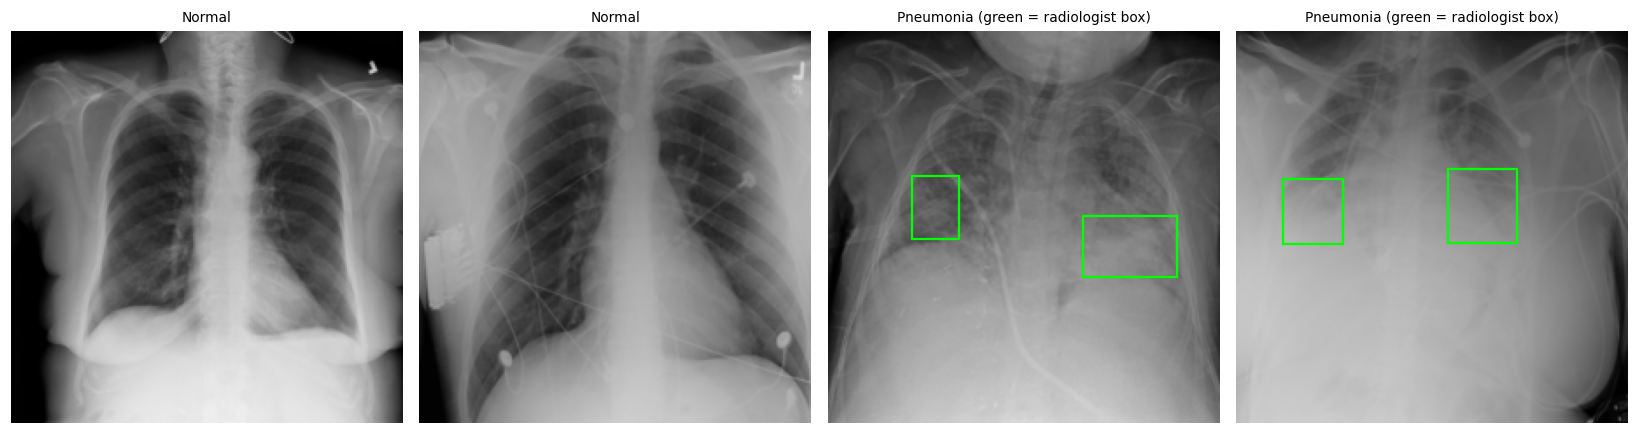

In [3]:
def body_box(a):
    # identical to the Kermany notebook: drop almost-black outer columns/rows, then trim CROP_MARGIN from every edge
    h, w = a.shape
    box = []
    for prof, n in ((a.mean(axis=0), w), (a.mean(axis=1), h)):
        keep_ = np.flatnonzero(prof > 0.2 * np.percentile(prof, 95))
        lo, hi = (int(keep_[0]), int(keep_[-1]) + 1) if len(keep_) else (0, n)
        if hi - lo < 0.5 * n:
            lo, hi = 0, n
        m = int((hi - lo) * CROP_MARGIN)
        box.append((lo + m, hi - m))
    (l, r), (t, b) = box
    return l, t, r, b


RESAMPLE = getattr(getattr(Image, "Resampling", Image), "BILINEAR")


def read_gray(path):
    if path.lower().endswith(".dcm"):
        ds = pydicom.dcmread(path)
        a = ds.pixel_array
        if a.ndim == 3:
            a = a.mean(axis=-1)
        if a.dtype != np.uint8:
            a = a.astype(np.float32)
            a = ((a - a.min()) / max(float(a.max() - a.min()), 1e-6) * 255.0).astype(np.uint8)
        if str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2")).upper() == "MONOCHROME1":
            a = 255 - a
        return Image.fromarray(a)
    with Image.open(path) as im:
        return im.convert("L")


def load_one(path):
    im = read_gray(path)
    w, h = im.size
    box = body_box(np.asarray(im))
    arr = np.asarray(im.crop(box).resize((IMG_SIZE, IMG_SIZE), RESAMPLE), dtype=np.uint8)
    return arr, box, (w, h)


t0 = time.time()
with ThreadPoolExecutor(max_workers=max(4, os.cpu_count() or 4)) as pool:
    loaded = list(pool.map(load_one, df["path"].tolist()))
X_all = np.stack([r[0] for r in loaded])[..., None]
CROP = np.array([r[1] for r in loaded], dtype=np.float64)            # (l, t, r, b) in original pixels
ORIG = np.array([r[2] for r in loaded], dtype=np.float64)            # (width, height)
y_all = df["label"].to_numpy().astype(np.int32)
del loaded
gc.collect()
print(f"Loaded {len(X_all)} images -> {X_all.shape}, {X_all.nbytes / 1e6:.0f} MB in {time.time() - t0:.0f} s")

# radiologists' boxes -> 224x224 model-input coordinates (boxes are given for 1024x1024 images)
row_of = {pid: i for i, pid in enumerate(df["patientId"])}
GT = {}
for pid, g in box_df[box_df["Target"] == 1].groupby("patientId"):
    i = row_of.get(pid)
    if i is None:
        continue
    l, t, r, b = CROP[i]
    scale = ORIG[i, 0] / 1024.0                                      # 1.0 for the original DICOM files
    sx, sy = IMG_SIZE / (r - l), IMG_SIZE / (b - t)
    lst = []
    for _, bb in g.iterrows():
        x0, y0 = (bb["x"] * scale - l) * sx, (bb["y"] * scale - t) * sy
        x1, y1 = ((bb["x"] + bb["width"]) * scale - l) * sx, ((bb["y"] + bb["height"]) * scale - t) * sy
        x0, y0, x1, y1 = max(0.0, x0), max(0.0, y0), min(float(IMG_SIZE), x1), min(float(IMG_SIZE), y1)
        if x1 > x0 and y1 > y0:
            lst.append((x0, y0, x1, y1))
    if lst:
        GT[i] = lst
print(f"Pneumonia images with at least one box: {len(GT)} of {int(y_all.sum())}")


def show_examples():
    rng = np.random.default_rng(SEEDS[0])
    pick = list(rng.choice(np.flatnonzero(y_all == 0), 2, replace=False)) + \
        list(rng.choice([i for i in GT], 2, replace=False))
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
    for ax, i in zip(axes, pick):
        ax.imshow(X_all[i, ..., 0], cmap="gray", vmin=0, vmax=255)
        for (x0, y0, x1, y1) in GT.get(i, []):
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5))
        ax.set_title(f"{CLASS_NAMES[y_all[i]]}" + (" (green = radiologist box)" if i in GT else ""), fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    save_fig(fig, "24_rsna_examples")


safe(show_examples)

## 4. Augmentation, input pipeline and DSRA-Net (identical to the Kermany v2 notebook)

In [4]:
augmenter = keras.Sequential([
    layers.RandomRotation(15 / 360, fill_mode="reflect", seed=SEEDS[0]),
    layers.RandomZoom(height_factor=(-0.20, 0.10), width_factor=(-0.20, 0.10), fill_mode="reflect", seed=SEEDS[0]),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEEDS[0]),
    layers.RandomBrightness(0.20, value_range=(0.0, 1.0), seed=SEEDS[0]),
    layers.RandomContrast(0.30, seed=SEEDS[0]),
], name="augmentation")


def random_resolution(x):
    s = tf.random.uniform([], 0.5, 1.0)
    size = tf.cast(tf.round(IMG_SIZE * s), tf.int32)
    small = tf.image.resize(x, tf.stack([size, size]), method="bilinear", antialias=True)
    return tf.image.resize(small, [IMG_SIZE, IMG_SIZE], method="bilinear")


def train_map(x, y):
    x = augmenter(x, training=True)
    x = tf.cond(tf.random.uniform([]) < 0.5, lambda: random_resolution(x), lambda: x)
    x = x + tf.random.normal(tf.shape(x), stddev=tf.random.uniform([], 0.0, 0.03))
    return tf.clip_by_value(x, 0.0, 1.0), y


def make_ds(idx, training, seed=42):
    ds = tf.data.Dataset.from_tensor_slices((X_all[idx], y_all[idx].astype(np.float32)))
    if training:
        ds = ds.shuffle(len(idx), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(train_map, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


class PerImageStandardization(layers.Layer):
    # subtract each image's own mean and divide by its own standard deviation (no trainable weights)
    def call(self, x):
        mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        std = tf.math.reduce_std(x, axis=[1, 2, 3], keepdims=True)
        return (x - mean) / (std + 1e-6)


def conv_bn_relu(x, filters, k, name):
    x = layers.Conv2D(filters, k, padding="same", use_bias=False, kernel_initializer="he_normal",
                      kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_conv")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_bn")(x)
    return layers.Activation("relu", name=f"{name}_relu")(x)


def dsg_block(x, filters, name="dsg"):
    a = conv_bn_relu(x, filters, 3, f"{name}_A")
    b = conv_bn_relu(x, filters, 5, f"{name}_B")
    u = layers.Add(name=f"{name}_fuse")([a, b])
    s = layers.GlobalAveragePooling2D(name=f"{name}_squeeze")(u)
    g = layers.Dense(filters, activation="sigmoid", kernel_regularizer=keras.regularizers.l2(L2_WEIGHT),
                     name=f"{name}_gate")(s)
    g4 = layers.Reshape((1, 1, filters), name=f"{name}_gate_reshape")(g)
    diff = layers.Subtract(name=f"{name}_diff")([a, b])
    gd = layers.Multiply(name=f"{name}_gated_diff")([diff, g4])
    return layers.Add(name=f"{name}_out")([b, gd])


def se_block(x, filters, name, ratio=8):
    s = layers.GlobalAveragePooling2D(name=f"{name}_squeeze")(x)
    s = layers.Dense(max(filters // ratio, 4), activation="relu",
                     kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_fc1")(s)
    w = layers.Dense(filters, activation="sigmoid",
                     kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_weights")(s)
    w4 = layers.Reshape((1, 1, filters), name=f"{name}_reshape")(w)
    return layers.Multiply(name=f"{name}_scale")([x, w4])


def res_se_block(x, filters, name):
    y = conv_bn_relu(x, filters, 3, f"{name}_c1")
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer="he_normal",
                      kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_c2_conv")(y)
    y = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_c2_bn")(y)
    y = se_block(y, filters, f"{name}_se")
    sc = layers.Conv2D(filters, 1, padding="same", use_bias=False, kernel_initializer="he_normal",
                       kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name=f"{name}_short_conv")(x)
    sc = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_short_bn")(sc)
    out = layers.Add(name=f"{name}_add")([y, sc])
    return layers.Activation("relu", name=f"{name}_out")(out)


def build_dsranet(input_shape=None):
    input_shape = input_shape or (IMG_SIZE, IMG_SIZE, 1)
    inp = keras.Input(shape=input_shape, name="input_cxr")
    x = PerImageStandardization(name="input_std")(inp)
    x = conv_bn_relu(x, 32, 3, "stem")
    x = layers.MaxPooling2D(2, name="stem_pool")(x)
    x = dsg_block(x, 32, "dsg")
    x = layers.MaxPooling2D(2, name="dsg_pool")(x)
    for i, c in enumerate([64, 128, 256], start=1):
        x = res_se_block(x, c, f"rs{i}")
        x = layers.MaxPooling2D(2, name=f"rs{i}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="head_gap")(x)
    x = layers.Dropout(0.5, name="head_drop1")(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(L2_WEIGHT), name="head_fc")(x)
    x = layers.Dropout(0.3, name="head_drop2")(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)
    return keras.Model(inp, out, name="DSRA_Net")


print(f"DSRA-Net: {build_dsranet().count_params():,} parameters")
keras.backend.clear_session()

I0000 00:00:1790315634.299515      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790315634.302376      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


DSRA-Net: 1,301,177 parameters


## 5. Train and test on 3 different patient splits
Each split: 70% train / 15% validation / 15% test (stratified). Adam 0.001, binary cross-entropy with class weights and
label smoothing 0.1, learning rate halved on plateau, early stopping (patience 10), best epoch kept (lowest validation loss).
Test: single model, no test-time augmentation, threshold 0.5.

In [5]:
def make_split(seed):
    idx = np.arange(len(df))
    tr, rest = train_test_split(idx, train_size=TRAIN_FRAC, stratify=y_all, random_state=seed)
    va, te = train_test_split(rest, train_size=VAL_FRAC / (1 - TRAIN_FRAC), stratify=y_all[rest], random_state=seed)
    return np.sort(tr), np.sort(va), np.sort(te)


def class_weights(labels):
    counts = np.bincount(labels, minlength=2)
    return {i: float(len(labels) / (2 * counts[i])) for i in range(2)}


def binary_metrics(y_true, y_prob, thr=THRESHOLD):
    y_true, y_prob = np.asarray(y_true).astype(int), np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / b if b else 0.0
    sens, spec, prec, npv = div(tp, tp + fn), div(tn, tn + fp), div(tp, tp + fp), div(tn, tn + fn)
    both = len(np.unique(y_true)) == 2
    return {"Accuracy": div(tp + tn, len(y_true)), "Balanced accuracy": (sens + spec) / 2,
            "Sensitivity": sens, "Specificity": spec, "Precision": prec, "NPV": npv,
            "F1": div(2 * prec * sens, prec + sens),
            "MCC": float(matthews_corrcoef(y_true, y_pred)) if both else 0.0,
            "AUC": float(roc_auc_score(y_true, y_prob)) if both else float("nan"),
            "PR-AUC": float(average_precision_score(y_true, y_prob)) if both else float("nan"),
            "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn)}


runs, histories = [], []
for k, seed in enumerate(SEEDS, start=1):
    elapsed_h = (time.time() - T0) / 3600
    if runs and elapsed_h + np.mean([r["minutes"] for r in runs]) / 60 > TIME_BUDGET_HOURS:
        print(f"Time guard: skipping split {k} (seed {seed}) - {elapsed_h:.1f} h used")
        continue
    tr, va, te = make_split(seed)
    print(f"\n========== Split {k}/{len(SEEDS)} (seed {seed}): train {len(tr)} | validation {len(va)} | test {len(te)} "
          f"| {elapsed_h:.1f} h used ==========")
    keras.backend.clear_session()
    gc.collect()
    keras.utils.set_random_seed(seed)
    m = build_dsranet()
    m.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
              loss=keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING),
              metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
              jit_compile=False)
    ckpt = os.path.join(MODEL_DIR, f"dsranet_rsna_split{k}.weights.h5")
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=ES_PATIENCE, restore_best_weights=True, verbose=1),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE, min_lr=1e-6, verbose=1),
                 keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True, verbose=0)]
    t0 = time.time()
    hist = m.fit(make_ds(tr, True, seed=seed), validation_data=make_ds(va, False), epochs=EPOCHS,
                 class_weight=class_weights(y_all[tr]), callbacks=callbacks, verbose=2)
    sec = time.time() - t0
    if os.path.exists(ckpt):
        m.load_weights(ckpt)
    h = pd.DataFrame(hist.history)
    h.insert(0, "epoch", np.arange(1, len(h) + 1))
    histories.append(h.assign(split=k, seed=seed))
    p = m.predict(make_ds(te, False), verbose=0).ravel()
    met = binary_metrics(y_all[te], p)
    runs.append({"split": k, "seed": seed, "train": len(tr), "validation": len(va), "test": len(te),
                 "epochs": len(h), "best_epoch": int(h.loc[h["val_loss"].idxmin(), "epoch"]),
                 "best_val_loss": float(h["val_loss"].min()), "minutes": sec / 60, **met,
                 "te_idx": te, "p_test": p})
    pd.DataFrame({"patientId": df.loc[te, "patientId"].values, "true": y_all[te], "prob_pneumonia": p}).to_csv(
        os.path.join(TAB_DIR, f"rsna_test_predictions_split{k}.csv"), index=False)
    print(f"Split {k}: accuracy {met['Accuracy']:.4f} | sensitivity {met['Sensitivity']:.4f} | specificity "
          f"{met['Specificity']:.4f} | F1 {met['F1']:.4f} | AUC {met['AUC']:.4f} | {sec / 60:.1f} min")
    del m
    gc.collect()

pd.concat(histories).to_csv(os.path.join(TAB_DIR, "rsna_training_history.csv"), index=False)
KEYS = ["Accuracy", "Balanced accuracy", "Sensitivity", "Specificity", "Precision", "NPV", "F1", "MCC", "AUC", "PR-AUC"]
per_split = pd.DataFrame([{k: r[k] for k in ["split", "seed", "train", "validation", "test", "epochs", "best_epoch",
                                             "minutes"] + KEYS + ["TP", "TN", "FP", "FN"]} for r in runs]).set_index("split")
save_table(per_split.round(6), "rsna_metrics_per_split", index=True)
summary_rows = {k: (f"{per_split[k].mean():.4f} ± {per_split[k].std(ddof=1):.4f}" if len(per_split) > 1
                    else f"{per_split[k].mean():.4f}") for k in KEYS}
summary_tab = pd.Series(summary_rows, name=f"DSRA-Net on RSNA (mean ± std over {len(per_split)} splits)").to_frame()
print("\nPER SPLIT")
display(per_split[KEYS + ["TP", "TN", "FP", "FN", "epochs", "minutes"]].round(4))
print("\nSUMMARY (test sets, single model, threshold 0.5)")
display(summary_tab)
save_table(summary_tab, "rsna_metrics_mean_std", index=True)


========== Split 1/3 (seed 42): train 10404 | validation 2229 | test 2230 | 0.1 h used ==========
Epoch 1/60
326/326 - 73s - 223ms/step - accuracy: 0.8139 - auc: 0.8850 - loss: 0.7863 - val_accuracy: 0.8560 - val_auc: 0.9403 - val_loss: 0.6669 - learning_rate: 0.0010
Epoch 2/60
326/326 - 59s - 182ms/step - accuracy: 0.8561 - auc: 0.9233 - loss: 0.6487 - val_accuracy: 0.8147 - val_auc: 0.9548 - val_loss: 0.6768 - learning_rate: 0.0010
Epoch 3/60
326/326 - 59s - 182ms/step - accuracy: 0.8776 - auc: 0.9385 - loss: 0.5668 - val_accuracy: 0.7106 - val_auc: 0.9613 - val_loss: 0.7390 - learning_rate: 0.0010
Epoch 4/60
326/326 - 60s - 185ms/step - accuracy: 0.8824 - auc: 0.9434 - loss: 0.5231 - val_accuracy: 0.8542 - val_auc: 0.9626 - val_loss: 0.5536 - learning_rate: 0.0010
Epoch 5/60
326/326 - 60s - 183ms/step - accuracy: 0.8949 - auc: 0.9499 - loss: 0.4881 - val_accuracy: 0.7371 - val_auc: 0.9565 - val_loss: 0.8737 - learning_rate: 0.0010
Epoch 6/60
326/326 - 60s - 183ms/step - accuracy: 0

,Accuracy,Balanced accuracy,Sensitivity,Specificity,Precision,NPV,F1,MCC,AUC,PR-AUC,TP,TN,FP,FN,epochs,minutes
split,,,,,,,,,,,,,,,,
1,0.9399,0.9369,0.9213,0.9526,0.9295,0.9469,0.9254,0.8751,0.9811,0.9780,831,1265,63,71,54,55.5863
2,0.9381,0.9292,0.8825,0.9759,0.9614,0.9244,0.9202,0.8720,0.9820,0.9778,796,1296,32,106,49,51.0115
3,0.9336,0.9261,0.8869,0.9654,0.9456,0.9263,0.9153,0.8620,0.9813,0.9740,800,1282,46,102,60,64.6880



SUMMARY (test sets, single model, threshold 0.5)


,DSRA-Net on RSNA (mean ± std over 3 splits)
Accuracy,0.9372 ± 0.0032
Balanced accuracy,0.9308 ± 0.0056
Sensitivity,0.8969 ± 0.0212
Specificity,0.9646 ± 0.0117
Precision,0.9455 ± 0.0159
NPV,0.9325 ± 0.0125
F1,0.9203 ± 0.0050
MCC,0.8697 ± 0.0068
AUC,0.9815 ± 0.0005
PR-AUC,0.9766 ± 0.0022


## 6. Classification report, confusion matrix, ROC curves
The confusion matrix and classification report are for the split whose model has the lowest validation loss
(chosen on validation data, not on the test set). ROC curves are shown for every split.

Analysed model: split 3 (seed 242), lowest validation loss 0.3075

              precision    recall  f1-score   support

      Normal     0.9263    0.9654    0.9454      1328
   Pneumonia     0.9456    0.8869    0.9153       902

    accuracy                         0.9336      2230
   macro avg     0.9360    0.9261    0.9304      2230
weighted avg     0.9341    0.9336    0.9333      2230



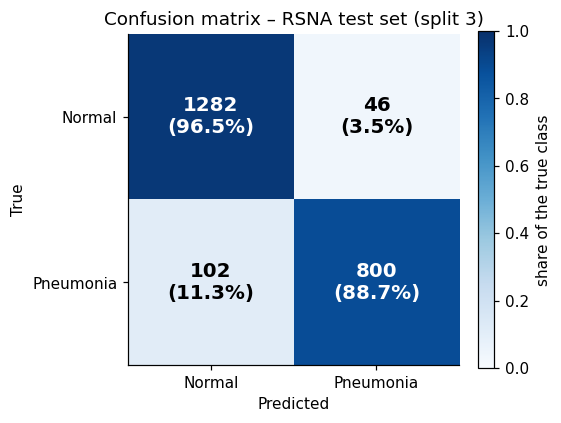

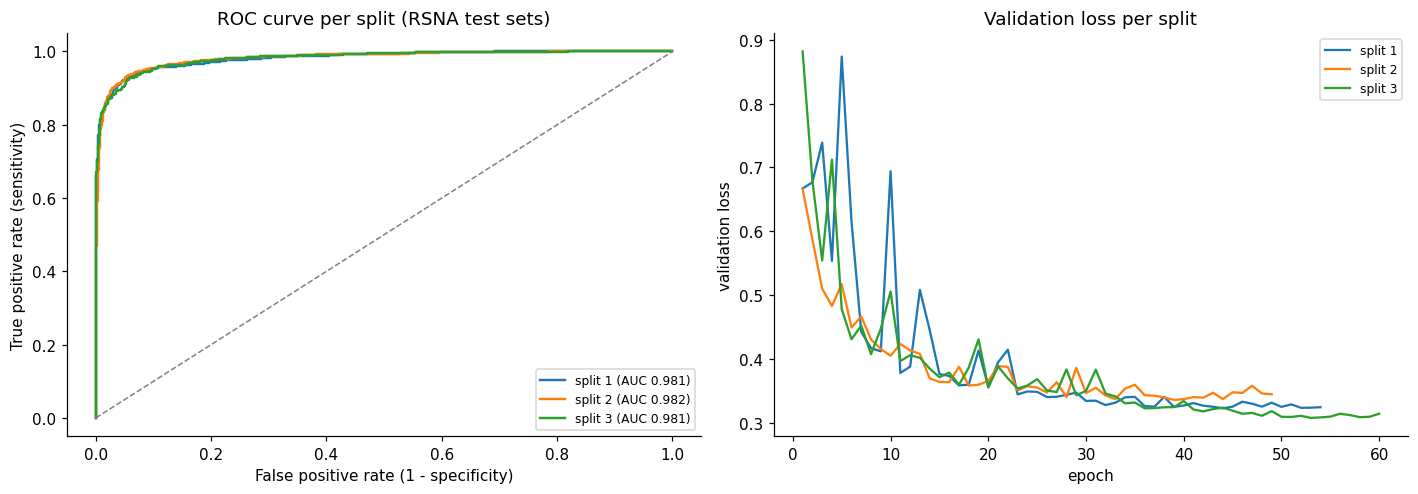

In [6]:
best = int(np.argmin([r["best_val_loss"] for r in runs]))
R = runs[best]
te_b, p_b = R["te_idx"], R["p_test"]
y_b = y_all[te_b]
yhat_b = (p_b >= THRESHOLD).astype(int)
print(f"Analysed model: split {R['split']} (seed {R['seed']}), lowest validation loss {R['best_val_loss']:.4f}\n")
print(classification_report(y_b, yhat_b, labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
save_table(pd.DataFrame(classification_report(y_b, yhat_b, labels=[0, 1], target_names=CLASS_NAMES, digits=4,
                                              zero_division=0, output_dict=True)).T.round(6),
           "rsna_classification_report", index=True)


def plot_confusion():
    cm = confusion_matrix(y_b, yhat_b, labels=[0, 1])
    cmn = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(5, 4.3))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * cmn[i, j]:.1f}%)", ha="center", va="center", fontsize=13,
                    fontweight="bold", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1], CLASS_NAMES)
    ax.set_yticks([0, 1], CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"Confusion matrix – RSNA test set (split {R['split']})")
    fig.colorbar(im, ax=ax, fraction=0.046, label="share of the true class")
    fig.tight_layout()
    save_fig(fig, "25_rsna_confusion_matrix")


def plot_roc_and_curves():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    for r in runs:
        fpr, tpr, _ = roc_curve(y_all[r["te_idx"]], r["p_test"])
        axes[0].plot(fpr, tpr, lw=1.6, label=f"split {r['split']} (AUC {r['AUC']:.3f})")
    axes[0].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
    axes[0].set_xlabel("False positive rate (1 - specificity)")
    axes[0].set_ylabel("True positive rate (sensitivity)")
    axes[0].set_title("ROC curve per split (RSNA test sets)")
    axes[0].legend(fontsize=8, loc="lower right")
    for h in histories:
        axes[1].plot(h["epoch"], h["val_loss"], lw=1.5, label=f"split {int(h['split'].iloc[0])}")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("validation loss")
    axes[1].set_title("Validation loss per split")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "26_rsna_roc_and_validation_loss")


safe(plot_confusion)
safe(plot_roc_and_curves)

## 7. Grad-CAM against the radiologists' boxes (pointing game)
For every pneumonia image in the test set of the analysed model, Grad-CAM shows where the model finds **pneumonia evidence**
(last Res-SE block, `rs3_out`). We check whether the **hottest point** of the map falls **inside a radiologist's box** (a "hit").
- **Hit rate:** share of pneumonia images with a hit.
- **Chance level:** the share of the image covered by boxes, i.e. the hit rate of a randomly placed point.
- **Heat inside boxes:** share of all Grad-CAM heat that falls inside the boxes (compare with the box area share).

Grad-CAM pointing game on the test set of split 3:


,images,hit rate %,chance level %,heat inside boxes %,box area %
group,,,,,
all pneumonia test images,902,68.8,14.0,34.9,14.0
detected (true positives),800,73.5,15.1,36.7,15.1
missed (false negatives),102,32.4,5.8,19.9,5.8


Hit rate well above the chance level = the model looks where the radiologists marked pneumonia.


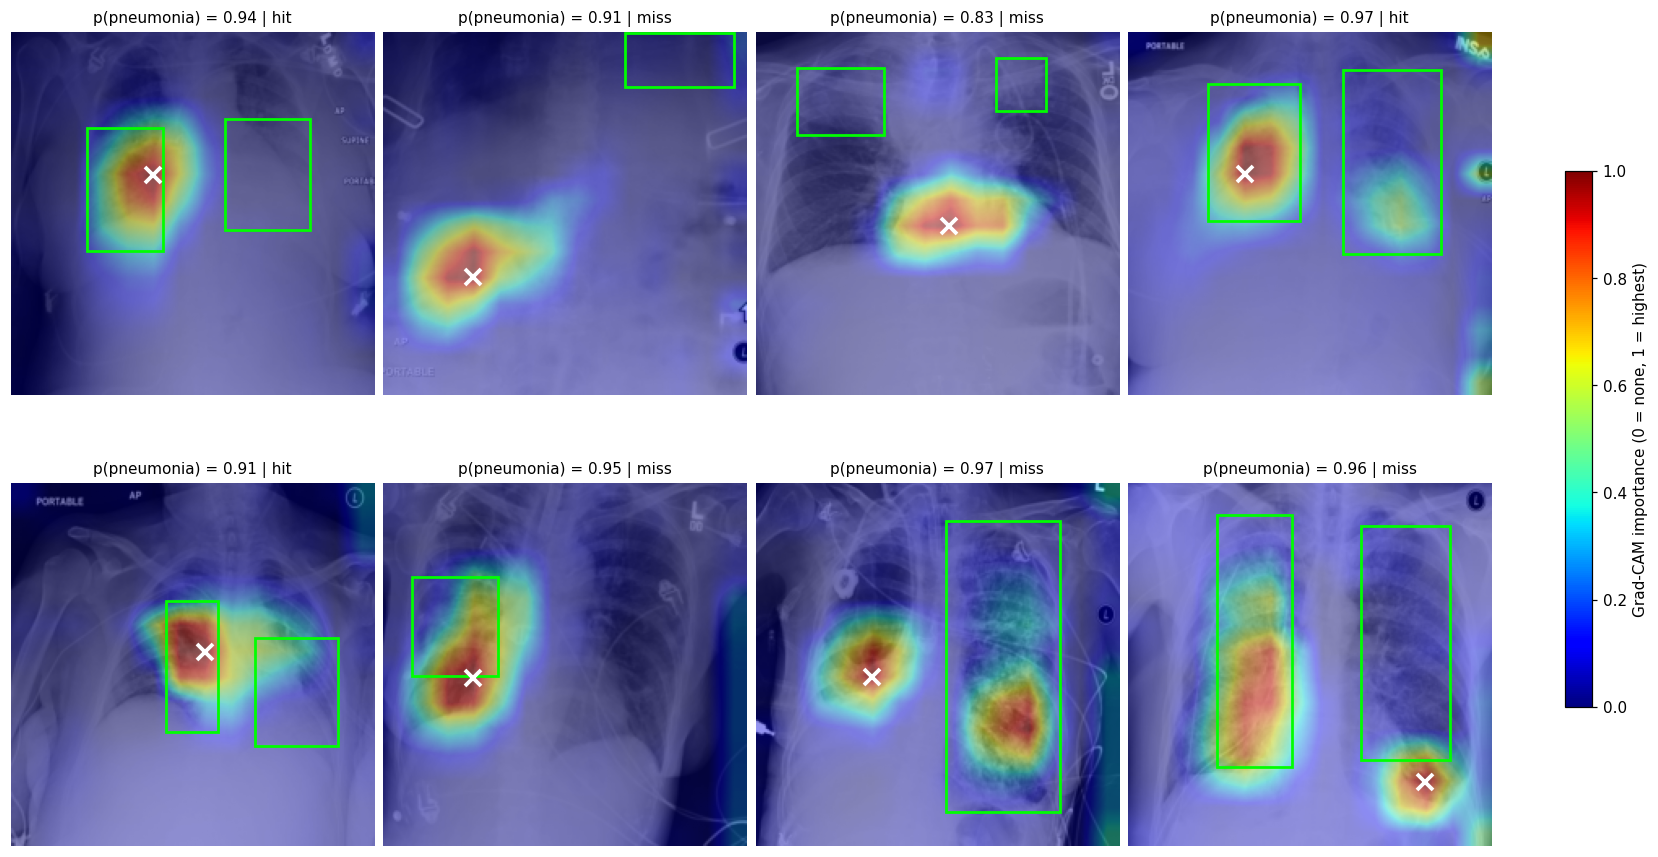

Green boxes = radiologists' pneumonia regions; white x = hottest point of the Grad-CAM map.


In [7]:
def gradcam_pointing_game():
    global PG_TABLE
    keras.backend.clear_session()
    model = build_dsranet()
    model.load_weights(os.path.join(MODEL_DIR, f"dsranet_rsna_split{R['split']}.weights.h5"))
    grad_model = keras.Model(model.inputs, [model.get_layer("rs3_out").output, model.output])

    def cam_batch(x):
        x = tf.convert_to_tensor(x, dtype=tf.float32)
        with tf.GradientTape() as tape:
            conv, pred = grad_model(x, training=False)
            target = pred[:, 0]                                      # evidence for pneumonia
        grads = tape.gradient(target, conv)
        weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(conv * weights, axis=-1))
        cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
        cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0]
        return np.asarray(cam, dtype=np.float32), np.asarray(pred[:, 0], dtype=np.float64)

    pos = np.array([i for i in te_b if i in GT])                     # pneumonia test images that have boxes
    cams, probs = [], []
    for s in range(0, len(pos), 32):
        c_, p_ = cam_batch(X_all[pos[s:s + 32]].astype(np.float32) / 255.0)
        cams.append(c_)
        probs.append(p_)
    cams, probs = np.concatenate(cams), np.concatenate(probs)

    rows = []
    for j, i in enumerate(pos):
        mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
        for (x0, y0, x1, y1) in GT[i]:
            mask[int(np.floor(y0)):int(np.ceil(y1)), int(np.floor(x0)):int(np.ceil(x1))] = True
        cam = cams[j]
        total = float(cam.sum())
        py, px = np.unravel_index(int(np.argmax(cam)), cam.shape)
        rows.append({"idx": int(i), "prob": float(probs[j]), "detected": bool(probs[j] >= THRESHOLD),
                     "has_heat": total > 0, "hit": bool(mask[py, px]) if total > 0 else False,
                     "heat_in_boxes": float(cam[mask].sum() / total) if total > 0 else np.nan,
                     "box_area": float(mask.mean()), "peak": (int(px), int(py))})
    pg = pd.DataFrame(rows)
    table = []
    for name, sub in [("all pneumonia test images", pg), ("detected (true positives)", pg[pg["detected"]]),
                      ("missed (false negatives)", pg[~pg["detected"]])]:
        if len(sub) == 0:
            continue
        table.append({"group": name, "images": len(sub),
                      "hit rate %": 100 * sub["hit"].mean(),
                      "chance level %": 100 * sub["box_area"].mean(),
                      "heat inside boxes %": 100 * sub["heat_in_boxes"].mean(),
                      "box area %": 100 * sub["box_area"].mean()})
    PG_TABLE = pd.DataFrame(table).set_index("group").round(1)
    print(f"Grad-CAM pointing game on the test set of split {R['split']}:")
    display(PG_TABLE)
    save_table(PG_TABLE, "rsna_gradcam_pointing_game", index=True)
    print("Hit rate well above the chance level = the model looks where the radiologists marked pneumonia.")

    # figure: 8 random pneumonia test images (fixed seed) with boxes, heatmap and hottest point
    rng = np.random.default_rng(SEEDS[0])
    pick = rng.choice(len(pos), size=min(8, len(pos)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(15, 8.2), layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, j in zip(axes.ravel(), pick):
        i = pos[j]
        ax.imshow(X_all[i, ..., 0], cmap="gray", vmin=0, vmax=255)
        ax.imshow(cams[j], cmap="jet", alpha=0.4, vmin=0, vmax=1)
        for (x0, y0, x1, y1) in GT[i]:
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.8))
        px, py = pg.loc[j, "peak"]
        ax.plot(px, py, marker="x", color="white", ms=11, mew=2.5)
        ax.set_title(f"p(pneumonia) = {probs[j]:.2f} | {'hit' if pg.loc[j, 'hit'] else 'miss'}", fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 1), cmap="jet"), ax=axes, shrink=0.6,
                 label="Grad-CAM importance (0 = none, 1 = highest)")
    save_fig(fig, "27_rsna_gradcam_vs_radiologist_boxes")
    print("Green boxes = radiologists' pneumonia regions; white x = hottest point of the Grad-CAM map.")


PG_TABLE = None
safe(gradcam_pointing_game)

## 8. Summary

In [8]:
out = {"dataset": "RSNA Pneumonia Detection Challenge (Lung Opacity vs Normal)", "images": int(len(df)),
       "normal": int((y_all == 0).sum()), "pneumonia": int((y_all == 1).sum()),
       "splits": [{k: (v if not isinstance(v, (np.floating, np.integer)) else v.item()) for k, v in r.items()
                   if k not in ("te_idx", "p_test")} for r in runs],
       "mean_std": summary_rows, "analysed_split": int(R["split"]),
       "gradcam_pointing_game": PG_TABLE.reset_index().to_dict(orient="records") if PG_TABLE is not None else None,
       "hours": round((time.time() - T0) / 3600, 2)}
with open(os.path.join(OUT_DIR, "rsna_results_summary.json"), "w") as f:
    json.dump(out, f, indent=2, default=str)

print(f"RSNA, {len(df)} images ({out['normal']} Normal / {out['pneumonia']} Pneumonia), {len(runs)} patient splits")
for k in ["Accuracy", "Sensitivity", "Specificity", "F1", "AUC"]:
    print(f"  {k:12s} {summary_rows[k]}")
if PG_TABLE is not None:
    row = PG_TABLE.iloc[0]
    print(f"\nGrad-CAM pointing game: hit rate {row['hit rate %']:.1f}% vs chance {row['chance level %']:.1f}%")
print(f"\nTotal time: {out['hours']} h. Files saved in {OUT_DIR}")

RSNA, 14863 images (8851 Normal / 6012 Pneumonia), 3 patient splits
  Accuracy     0.9372 ± 0.0032
  Sensitivity  0.8969 ± 0.0212
  Specificity  0.9646 ± 0.0117
  F1           0.9203 ± 0.0050
  AUC          0.9815 ± 0.0005

Grad-CAM pointing game: hit rate 68.8% vs chance 14.0%

Total time: 2.93 h. Files saved in /kaggle/working/outputs


I0000 00:00:1790326345.173512     138 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Split 3: test accuracy 0.9336 (should match the table above)
Normal example: patient 6a87f637-edc6-4ba4-99a3-65ad4de67f71 -> p(pneumonia) = 0.061
Pneumonia example: patient 804249b1-2260-408b-9aaf-3f2e3eeae93f -> p(pneumonia) = 0.954


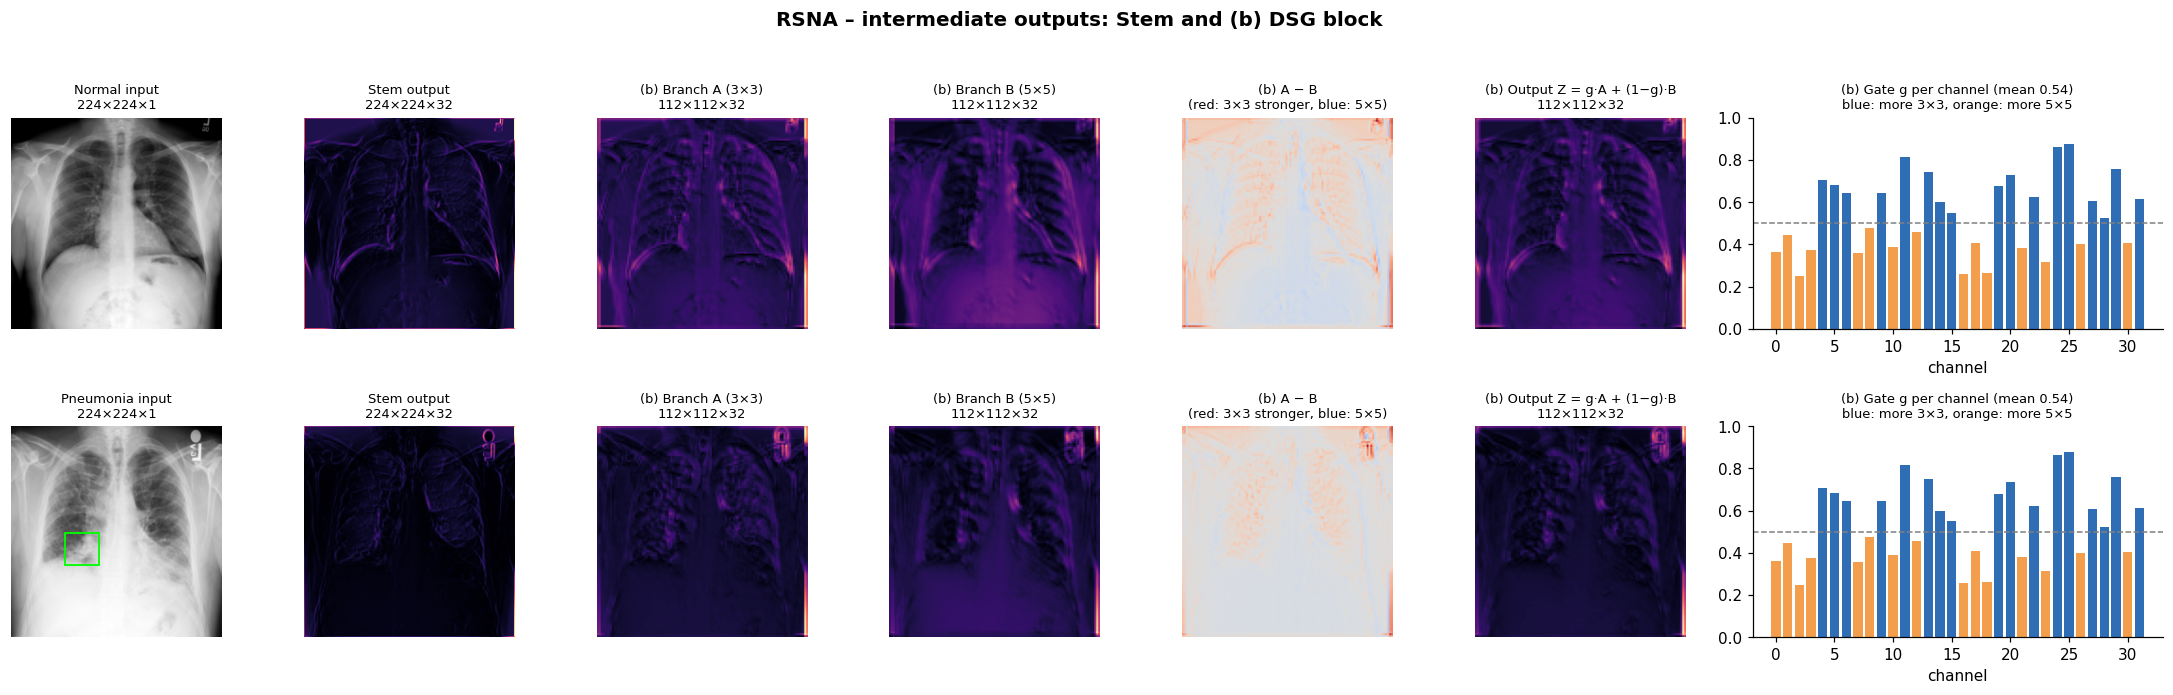

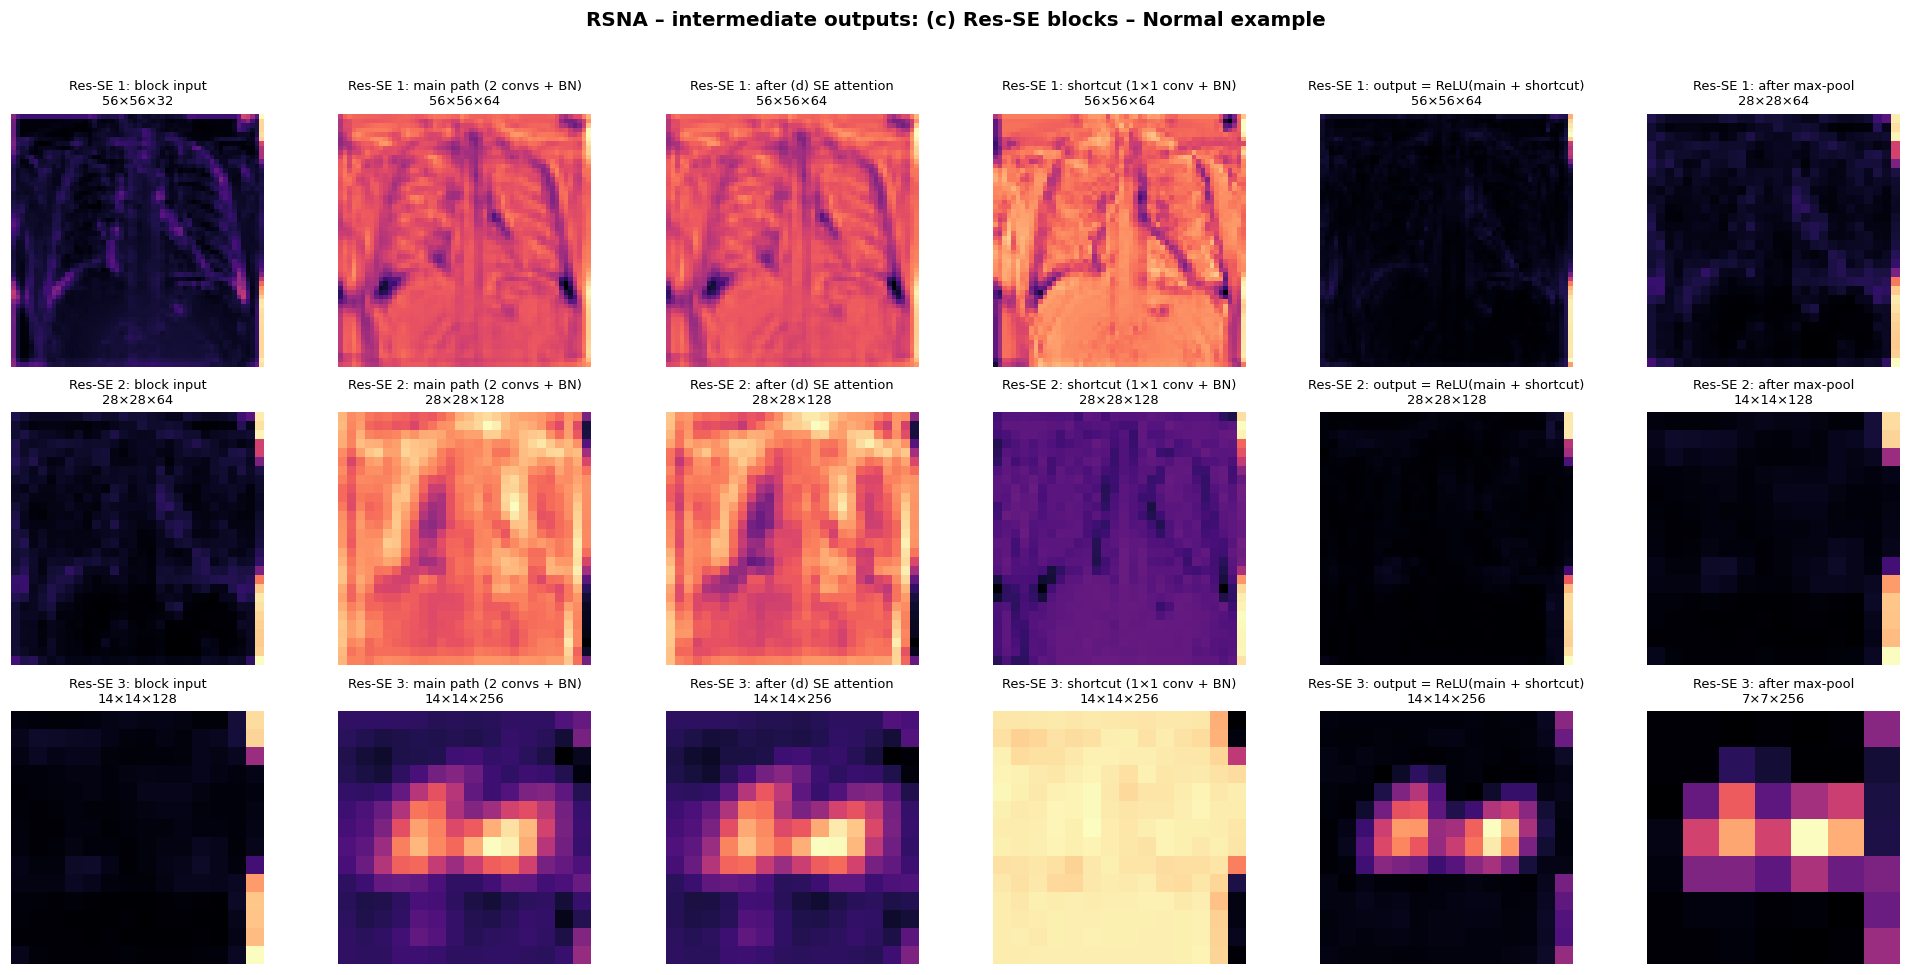

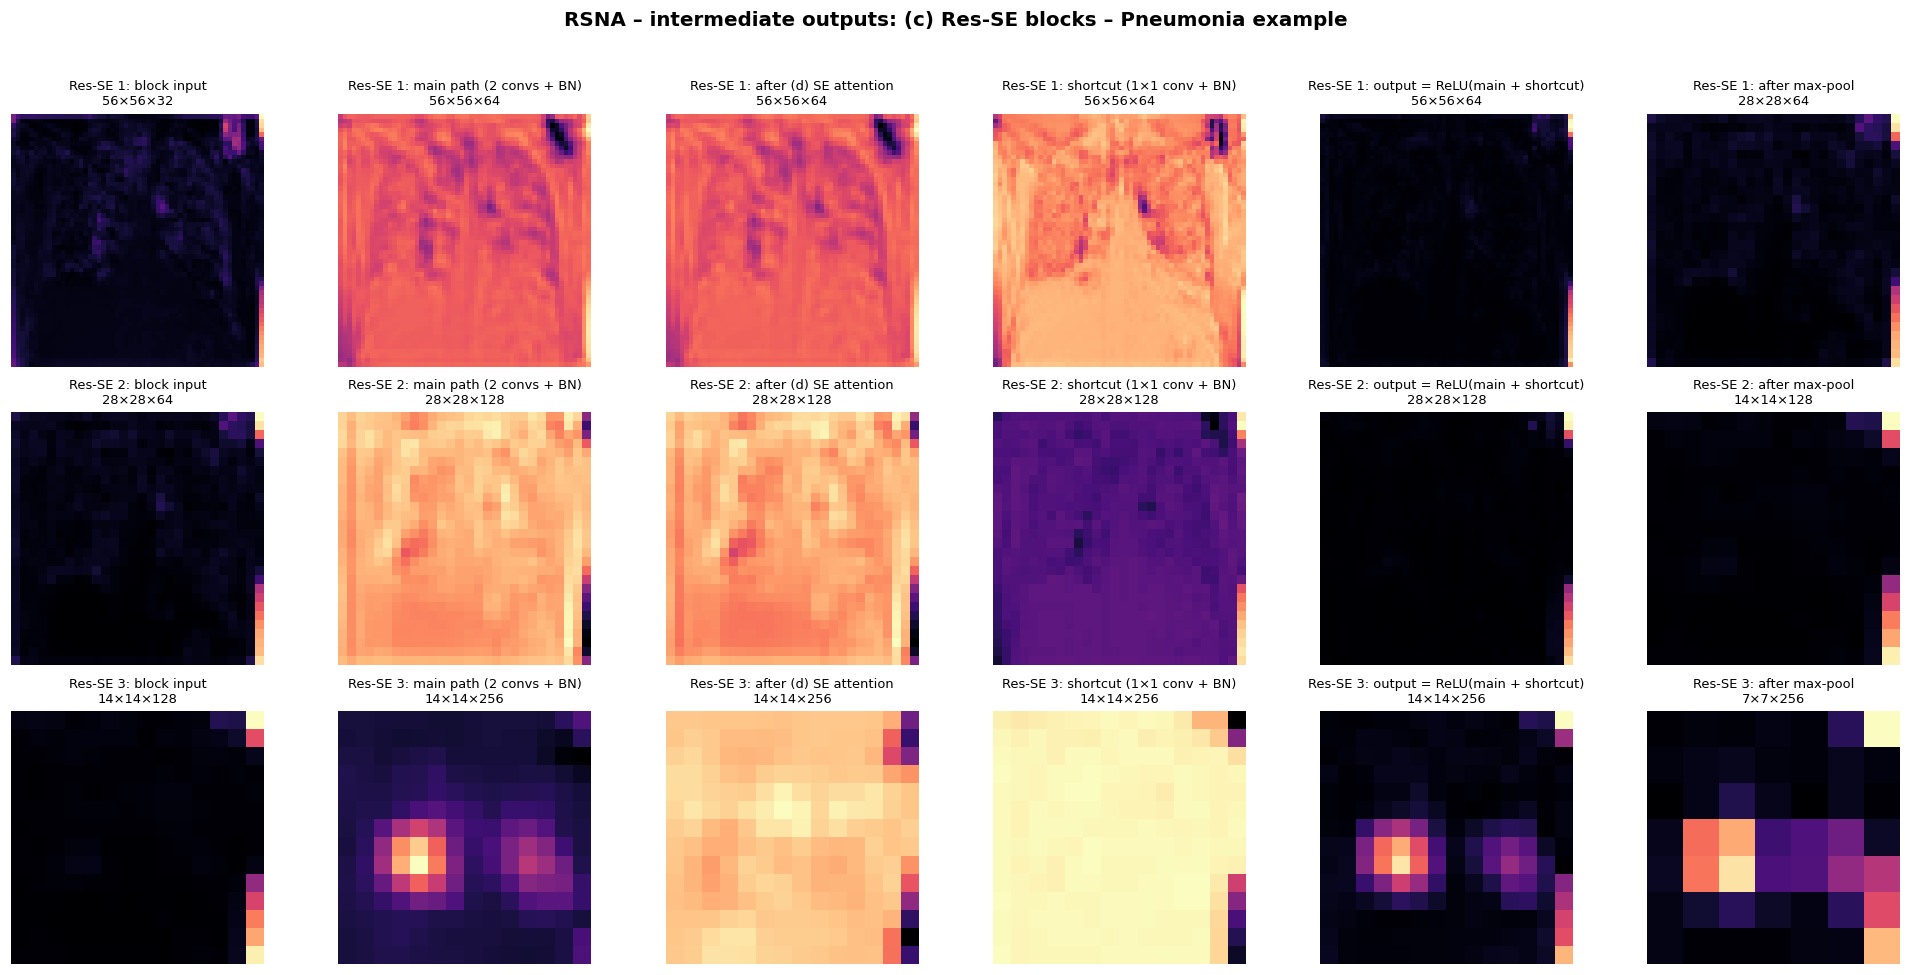

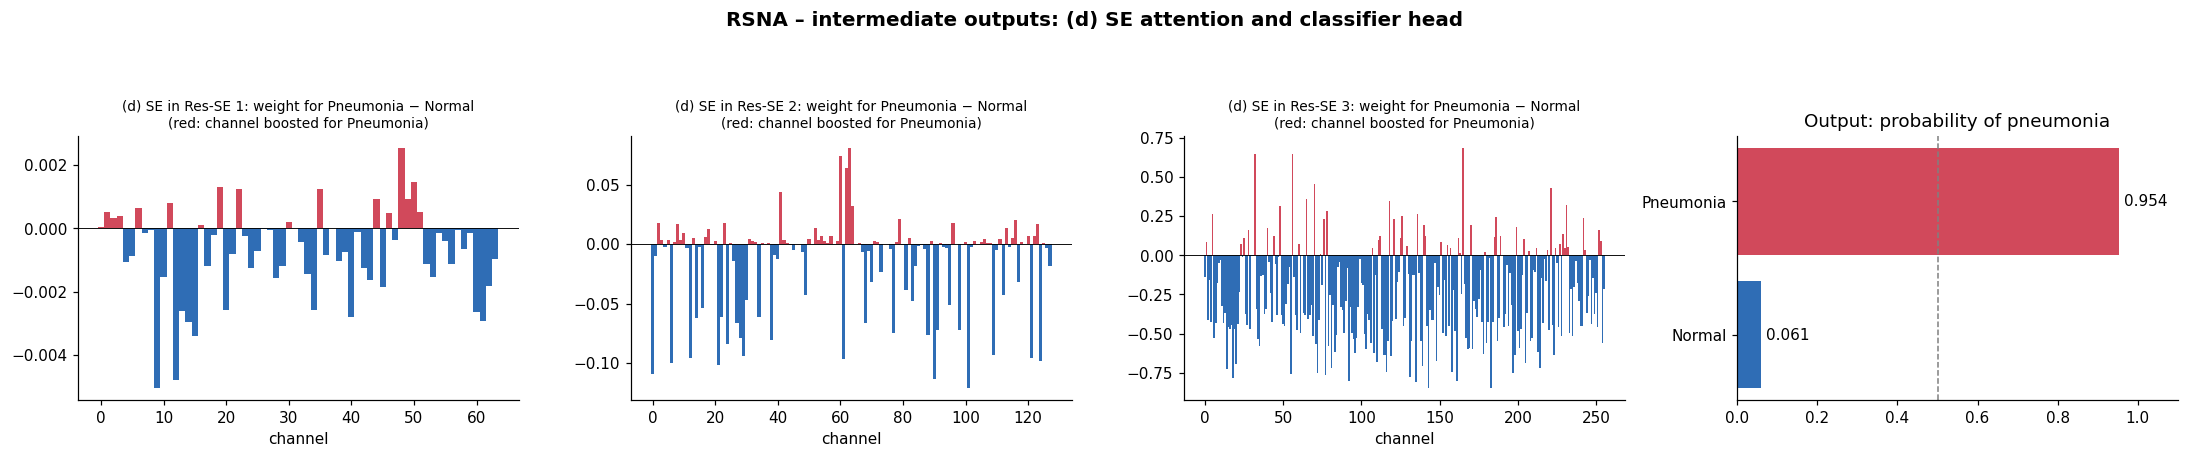

In [9]:
# ===== RSNA: intermediate outputs of every block (one Normal + one Pneumonia test image) =====
split_no = int(R["split"]) if "R" in globals() else 3      # split with the lowest validation loss (split 3 in your run)
seed = SEEDS[split_no - 1]
wname = f"dsranet_rsna_split{split_no}.weights.h5"
wpath = os.path.join(MODEL_DIR, wname)
if not os.path.exists(wpath):
    wpath = next((os.path.join(dp, wname) for dp, _, fs in os.walk("/kaggle/input") if wname in fs), None)
keras.backend.clear_session()
model = build_dsranet()
model.load_weights(wpath)

# same test split as in training
idx_all = np.arange(len(df))
_, rest = train_test_split(idx_all, train_size=TRAIN_FRAC, stratify=y_all, random_state=seed)
_, te_s = train_test_split(rest, train_size=VAL_FRAC / (1 - TRAIN_FRAC), stratify=y_all[rest], random_state=seed)
te_s = np.sort(te_s)
p_s = model.predict(X_all[te_s].astype(np.float32) / 255.0, batch_size=32, verbose=0).ravel()
y_s, yhat_s = y_all[te_s], (p_s >= THRESHOLD).astype(int)
print(f"Split {split_no}: test accuracy {np.mean(yhat_s == y_s):.4f} (should match the table above)")

PROBE = {"stem": "stem_relu", "dsg_A": "dsg_A_relu", "dsg_B": "dsg_B_relu", "dsg_gate": "dsg_gate",
         "dsg_Z": "dsg_out", "prob": "output"}
for i in (1, 2, 3):
    PROBE.update({f"rs{i}_in": "dsg_pool" if i == 1 else f"rs{i - 1}_pool", f"rs{i}_main": f"rs{i}_c2_bn",
                  f"rs{i}_se_w": f"rs{i}_se_weights", f"rs{i}_se_out": f"rs{i}_se_scale",
                  f"rs{i}_short": f"rs{i}_short_bn", f"rs{i}_out": f"rs{i}_out", f"rs{i}_pool": f"rs{i}_pool"})
order = [l.name for l in model.layers]
probe_layers = sorted(set(PROBE.values()), key=order.index)
probe = keras.Model(model.inputs, [model.get_layer(n).output for n in probe_layers])


def pick_example(label):  # a correctly classified image with a typical probability
    ok = np.where((y_s == label) & (yhat_s == label))[0]
    cand = ok if len(ok) else np.where(y_s == label)[0]
    return int(cand[np.argmin(np.abs(p_s[cand] - np.median(p_s[cand])))])


names = ["Normal", "Pneumonia"]
pos = [pick_example(0), pick_example(1)]
idx = [int(te_s[j]) for j in pos]
x_ex = X_all[idx].astype(np.float32) / 255.0
outs = probe.predict(x_ex, verbose=0)
outs = outs if isinstance(outs, (list, tuple)) else [outs]
by_layer = dict(zip(probe_layers, outs))
acts = {k: np.asarray(by_layer[v]) for k, v in PROBE.items()}
for n, j, i in zip(names, pos, idx):
    print(f"{n} example: patient {df.loc[i, 'patientId']} -> p(pneumonia) = {p_s[j]:.3f}")

shp = lambda a: "×".join(str(s) for s in a.shape)


def show(ax, img, title, cmap="magma", sym=False):
    if sym:
        v = float(np.abs(img).max()) or 1.0
        ax.imshow(img, cmap=cmap, vmin=-v, vmax=v)
    else:
        ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=8.5)
    ax.axis("off")


# Figure 1: stem and (b) DSG block
fig = plt.figure(figsize=(20, 6.4))
gs = fig.add_gridspec(2, 7, width_ratios=[1, 1, 1, 1, 1, 1, 1.7])
for r, n in enumerate(names):
    a = {k: v[r] for k, v in acts.items()}
    ax0 = fig.add_subplot(gs[r, 0])
    show(ax0, x_ex[r, ..., 0], f"{n} input\n{shp(x_ex[r])}", "gray")
    for (x0, y0, x1, y1) in GT.get(idx[r], []):
        ax0.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.2))
    panels = [(a["stem"].mean(-1), f"Stem output\n{shp(a['stem'])}", "magma", False),
              (a["dsg_A"].mean(-1), f"(b) Branch A (3×3)\n{shp(a['dsg_A'])}", "magma", False),
              (a["dsg_B"].mean(-1), f"(b) Branch B (5×5)\n{shp(a['dsg_B'])}", "magma", False),
              ((a["dsg_A"] - a["dsg_B"]).mean(-1), "(b) A − B\n(red: 3×3 stronger, blue: 5×5)", "coolwarm", True),
              (a["dsg_Z"].mean(-1), f"(b) Output Z = g·A + (1−g)·B\n{shp(a['dsg_Z'])}", "magma", False)]
    for c, (img, title, cmap, sym) in enumerate(panels, start=1):
        show(fig.add_subplot(gs[r, c]), img, title, cmap, sym)
    ax = fig.add_subplot(gs[r, 6])
    g = a["dsg_gate"]
    ax.bar(np.arange(len(g)), g, color=np.where(g >= 0.5, C_NORMAL, "#F29E4C"))
    ax.axhline(0.5, color="grey", ls="--", lw=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("channel")
    ax.set_title(f"(b) Gate g per channel (mean {g.mean():.2f})\nblue: more 3×3, orange: more 5×5", fontsize=8.5)
fig.suptitle("RSNA – intermediate outputs: Stem and (b) DSG block", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "28_rsna_intermediate_stem_dsg")

# Figures 2-3: (c) Res-SE blocks, one figure per example
for s_i, n in enumerate(names):
    a = {k: v[s_i] for k, v in acts.items()}
    fig, axes = plt.subplots(3, 6, figsize=(18, 9))
    for b in range(3):
        i = b + 1
        cols = [(f"rs{i}_in", "block input"), (f"rs{i}_main", "main path (2 convs + BN)"),
                (f"rs{i}_se_out", "after (d) SE attention"), (f"rs{i}_short", "shortcut (1×1 conv + BN)"),
                (f"rs{i}_out", "output = ReLU(main + shortcut)"), (f"rs{i}_pool", "after max-pool")]
        for c, (key, lab) in enumerate(cols):
            show(axes[b, c], a[key].mean(-1), f"Res-SE {i}: {lab}\n{shp(a[key])}")
    fig.suptitle(f"RSNA – intermediate outputs: (c) Res-SE blocks – {n} example", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    save_fig(fig, f"29_rsna_intermediate_resse_{n.lower()}")

# Figure 4: (d) SE attention and the classifier output
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for b in range(3):
    i = b + 1
    s = acts[f"rs{i}_se_w"]
    diff = s[1] - s[0]
    axes[b].bar(np.arange(len(diff)), diff, width=1.0, color=np.where(diff >= 0, C_PNEU, C_NORMAL))
    axes[b].axhline(0, color="black", lw=0.6)
    axes[b].set_xlabel("channel")
    axes[b].set_title(f"(d) SE in Res-SE {i}: weight for Pneumonia − Normal\n(red: channel boosted for Pneumonia)", fontsize=9)
probs = acts["prob"].ravel()
bars = axes[3].barh(names, probs, color=[C_NORMAL, C_PNEU])
axes[3].bar_label(bars, labels=[f"{v:.3f}" for v in probs], padding=3)
axes[3].axvline(THRESHOLD, color="grey", ls="--", lw=1)
axes[3].set_xlim(0, 1.1)
axes[3].set_title("Output: probability of pneumonia")
fig.suptitle("RSNA – intermediate outputs: (d) SE attention and classifier head", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))
save_fig(fig, "30_rsna_intermediate_se_head")